# 04 — Classification (favorite → purchase)

Random Forest (statistical baseline) vs MLP (neural).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from corevent_analytics.config import get_settings
from corevent_analytics.data import load_data, build_classification_frame
from corevent_analytics.models import run_classification

sns.set_theme(style="whitegrid")
settings = get_settings()
tables, source = load_data(settings)
x, y, feature_cols = build_classification_frame(tables)
result = run_classification(
    x,
    y,
    test_size=settings.test_size,
    random_state=settings.random_state,
)
print("source:", source, "| samples:", result["n_samples"])
print("class balance:", result["class_balance"])
feature_cols[:10]

source: synthetic | samples: 3000
class balance: {1: 0.5276666666666666, 0: 0.4723333333333333}


['age',
 'account_age_days',
 'n_favorites',
 'cat_music',
 'cat_sports',
 'cat_tech',
 'cat_business',
 'cat_education',
 'cat_art_culture',
 'cat_gastronomy']

In [2]:
rows = []
for name in ("random_forest", "mlp"):
    metrics = result.get(name, {}).get("metrics", {})
    if metrics:
        rows.append({
            "model": name,
            "accuracy": metrics["accuracy"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
        })
pd.DataFrame(rows)

,model,accuracy,precision,recall,f1
0,random_forest,0.533333,0.563187,0.517677,0.539474
1,mlp,0.596000,0.628809,0.573232,0.599736


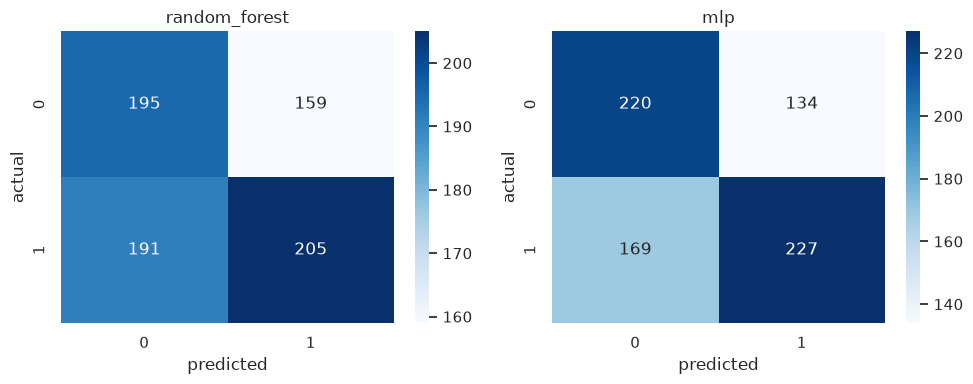

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ("random_forest", "mlp")):
    cm = result.get(name, {}).get("metrics", {}).get("confusion_matrix")
    if cm:
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
        ax.set_title(name)
        ax.set_xlabel("predicted")
        ax.set_ylabel("actual")
fig.tight_layout()
plt.show()

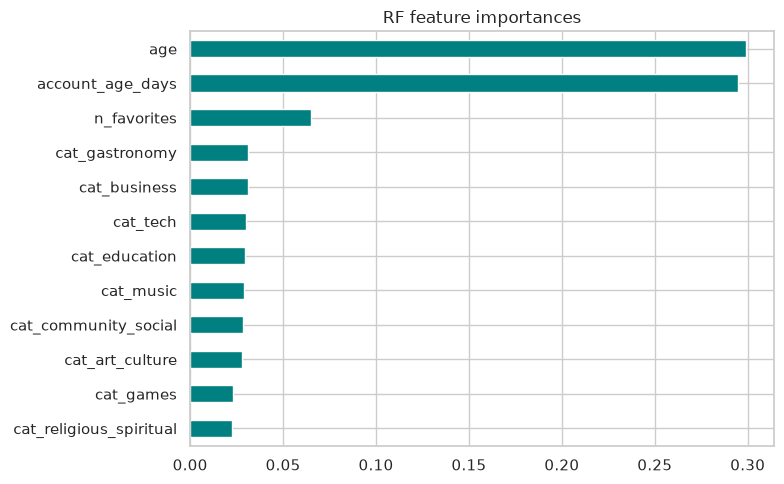

In [4]:
importances = result.get("random_forest", {}).get("feature_importances")
if importances:
    top = pd.Series(importances).head(12).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    top.plot(kind="barh", ax=ax, color="teal")
    ax.set_title("RF feature importances")
    fig.tight_layout()
    plt.show()
else:
    print("No RF importances")